#  ClimaSignal-XAI
## Climate Data Collection

**Project objective:** Investigate whether digital signal processing improves climate anomaly detection and evaluate the reliability of explainable machine learning methods.

**Data source:** NASA POWER — Prediction Of Worldwide Energy Resources.

**Study locations:** Amman, Irbid, and Aqaba, Jordan.

**Primary variable:** Daily mean air temperature at 2 meters (`T2M`).

**Workflow:**
1. Retrieve daily climate observations.
2. Validate data quality and missing values.
3. Explore temporal patterns and seasonal variation.
4. Establish a reproducible baseline for anomaly detection.
5. Compare signal-processing methods and machine-learning models.
6. Evaluate model explanations and their stability.

**Research principle:** No performance improvement will be claimed before conducting a fair experimental comparison.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Data collection notebook is ready.")

Pandas: 2.2.3
NumPy: 2.1.3
Data collection notebook is ready.


In [3]:
import requests

url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "T2M",
    "community": "AG",
    "longitude": 35.9106,
    "latitude": 31.9539,
    "start": "20200101",
    "end": "20201231",
    "format": "JSON"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)

response.raise_for_status()

result = response.json()

print("Response received:", "properties" in result)
print("Requested location: Amman, Jordan")

HTTP status: 200
Response received: True
Requested location: Amman, Jordan


In [4]:
import requests
import json
import pandas as pd
from pathlib import Path
from IPython.display import display

# Use the project directory established in Notebook 01
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

locations = {
    "Amman": {"latitude": 31.9539, "longitude": 35.9106},
    "Irbid": {"latitude": 32.5556, "longitude": 35.8500},
    "Aqaba": {"latitude": 29.5321, "longitude": 35.0063},
}

BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

start_date = "20200101"
end_date = "20201231"

all_data = []
raw_responses = {}

for city, coordinates in locations.items():
    params = {
        "parameters": "T2M",
        "community": "AG",
        "latitude": coordinates["latitude"],
        "longitude": coordinates["longitude"],
        "start": start_date,
        "end": end_date,
        "format": "JSON",
        "time-standard": "UTC",
    }

    response = requests.get(BASE_URL, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()

    if "properties" not in payload:
        raise ValueError(f"Unexpected API response for {city}")

    raw_responses[city] = payload

    # Preserve the original API response
    raw_path = RAW_DIR / f"{city.lower()}_nasa_power_raw_2020.json"
    with raw_path.open("w", encoding="utf-8") as file:
        json.dump(payload, file, ensure_ascii=False, indent=2)

    temperature_data = payload["properties"]["parameter"]["T2M"]

    city_df = pd.DataFrame({
        "date": pd.to_datetime(list(temperature_data.keys()), format="%Y%m%d"),
        "temperature_c": list(temperature_data.values()),
        "city": city,
    })

    all_data.append(city_df)

    print(f"{city}: {len(city_df)} daily records downloaded.")

climate_df = pd.concat(all_data, ignore_index=True)

print("\nCombined dataset shape:", climate_df.shape)
display(climate_df.head())

Amman: 366 daily records downloaded.
Irbid: 366 daily records downloaded.
Aqaba: 366 daily records downloaded.

Combined dataset shape: (1098, 3)


,date,temperature_c,city
0,2020-01-01,11.75,Amman
1,2020-01-02,11.92,Amman
2,2020-01-03,9.84,Amman
3,2020-01-04,9.52,Amman
4,2020-01-05,10.75,Amman


In [6]:
print("Dataset information:")
climate_df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1098 entries, 0 to 1097
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1098 non-null   datetime64[ns]
 1   temperature_c  1098 non-null   float64       
 2   city           1098 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 25.9+ KB


In [10]:
print("Missing values:")
display(climate_df.isna().sum().to_frame("missing_count"))

Missing values:


,missing_count
date,0
temperature_c,0
city,0


In [11]:
print("Duplicate rows:", climate_df.duplicated().sum())

Duplicate rows: 0


In [17]:
import pandas as pd

dataset_path = RAW_DIR / "jordan_climate_temperature_2020.csv"

climate_df = pd.read_csv(dataset_path, parse_dates=["date"])

display(climate_df.head(10))
print("Dataset shape:", climate_df.shape)

,date,temperature_c,city
0,2020-01-01,11.75,Amman
1,2020-01-02,11.92,Amman
2,2020-01-03,9.84,Amman
3,2020-01-04,9.52,Amman
4,2020-01-05,10.75,Amman
5,2020-01-06,11.02,Amman
6,2020-01-07,10.89,Amman
7,2020-01-08,9.87,Amman
8,2020-01-09,10.06,Amman
9,2020-01-10,9.36,Amman


Dataset shape: (1098, 3)


In [12]:
print("Date range:")
print(climate_df["date"].min(), "to", climate_df["date"].max())

Date range:
2020-01-01 00:00:00 to 2020-12-31 00:00:00


In [13]:
print("Records per city:")
display(climate_df.groupby("city").size().to_frame("records"))

Records per city:


,records
city,
Amman,366
Aqaba,366
Irbid,366


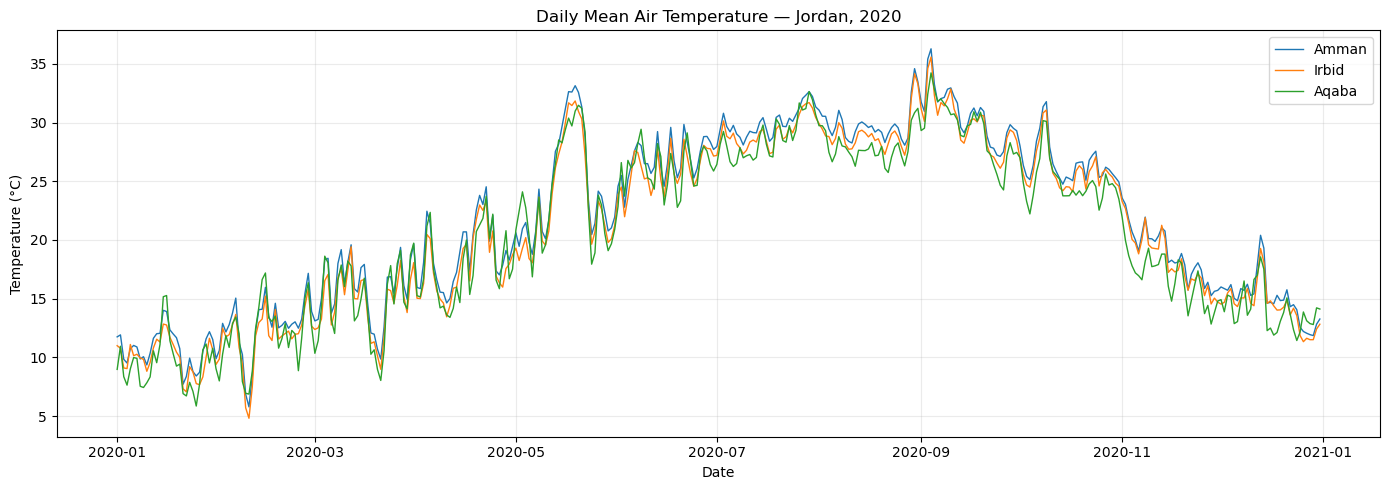

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

for city in locations:
    city_data = climate_df[climate_df["city"] == city]
    plt.plot(
        city_data["date"],
        city_data["temperature_c"],
        label=city,
        linewidth=1
    )

plt.title("Daily Mean Air Temperature — Jordan, 2020")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [15]:
csv_path = RAW_DIR / "jordan_climate_temperature_2020.csv"
climate_df.to_csv(csv_path, index=False)

print("Saved to:", csv_path)
print("File exists:", csv_path.exists())

Saved to: C:\Users\user\data\raw\jordan_climate_temperature_2020.csv
File exists: True
